**Nombre:**

*M.Fernanda García*

**ESCOM-IPN**

Regresión lineal

**Analicen el dataset:**

World Happiness Report https://www.kaggle.com/datasets/unsdsn/world-happiness

Objetivo: predecir índice de felicidad

## 1. Importar bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, to_rgba

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Semilla para que los resultados sean reproducibles

In [ ]:
SEMILLA = 42

Colores para gráficos

In [ ]:
AZUL = "#06BED6"
MORADO = "#8500F2"
ROSA = "#ED009A"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#b5b4ae",
    "axes.titleweight": "bold",
    "axes.axisbelow": True,
})
pd.set_option("display.precision", 3)

## 2. Cargar dataset

Al descargar el zip de Kaggle, aparecen varios csv, desde 2015 - 2019, usaremos el más reciente para el análisis

In [ ]:
df = pd.read_csv("2019.csv")

In [ ]:
df.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [ ]:
print(df.shape)
print(df.isnull().sum())

(156, 9)
Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64


Con estos resultados podemos observar que el dataset tiene 156 países, que serían las filas, y 9 columnas, y no tiene valores nulos. El Score es la variable objetivo, que es el índice de felicidad. Overall rank y Country or region no nos sirven como variables predictoras, ya que el ranking se calcula a partir del mismo Score (usarlo sería hacer trampa) y el país solo nos ayuda a identificar la fila. Además, elegimos el año 2019 porque, aunque revisando comentarios de la página algunos decían que los de 2018 y 2019 no servían, después una persona juntó todos los años en una sola tabla con una columna de año, y él mismo aclara que, según el año, algunas columnas quedan vacías (2018 y 2019 no tienen Region, Standard Error ni Dystopia Residual). Para nuestro objetivo eso no es un problema, porque 2019 sí tiene el Score y los seis factores completos; por ello se decidió usar ese año. Además, este año no tiene columnas derivadas del score como las de 2015 a 2017 (Dystopia Residual, Standard Error o los intervalos de confianza), que podrían causar fuga de información.

## 3. Exploración de datos (EDA)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Overall rank,156.0,78.500,45.177,1.000,39.750,78.500,117.250,156.000
Score,156.0,5.407,1.113,2.853,4.545,5.380,6.184,7.769
GDP per capita,156.0,0.905,0.398,0.000,0.603,0.960,1.233,1.684
Social support,156.0,1.209,0.299,0.000,1.056,1.272,1.452,1.624
Healthy life expectancy,156.0,0.725,0.242,0.000,0.548,0.789,0.882,1.141
Freedom to make life choices,156.0,0.393,0.143,0.000,0.308,0.417,0.507,0.631
Generosity,156.0,0.185,0.095,0.000,0.109,0.177,0.248,0.566
Perceptions of corruption,156.0,0.111,0.095,0.000,0.047,0.085,0.141,0.453


In [ ]:
print("Filas duplicadas:", df.duplicated().sum())
print("Países repetidos:", df["Country or region"].duplicated().sum())

Filas duplicadas: 0
Países repetidos: 0


Columnas numéricas que vamos a explorar (sin el ranking)

In [ ]:
COLUMNAS_EDA = ["Score", "GDP per capita", "Social support", "Healthy life expectancy",
                "Freedom to make life choices", "Generosity", "Perceptions of corruption"]

Etiquetas en español para títulos y ejes de gráficas

In [ ]:
ETIQUETAS = {
    "Score": "Felicidad (Score)",
    "GDP per capita": "PIB per cápita",
    "Social support": "Apoyo social",
    "Healthy life expectancy": "Esperanza de vida saludable",
    "Freedom to make life choices": "Libertad para decidir",
    "Generosity": "Generosidad",
    "Perceptions of corruption": "Percepción de corrupción",
}


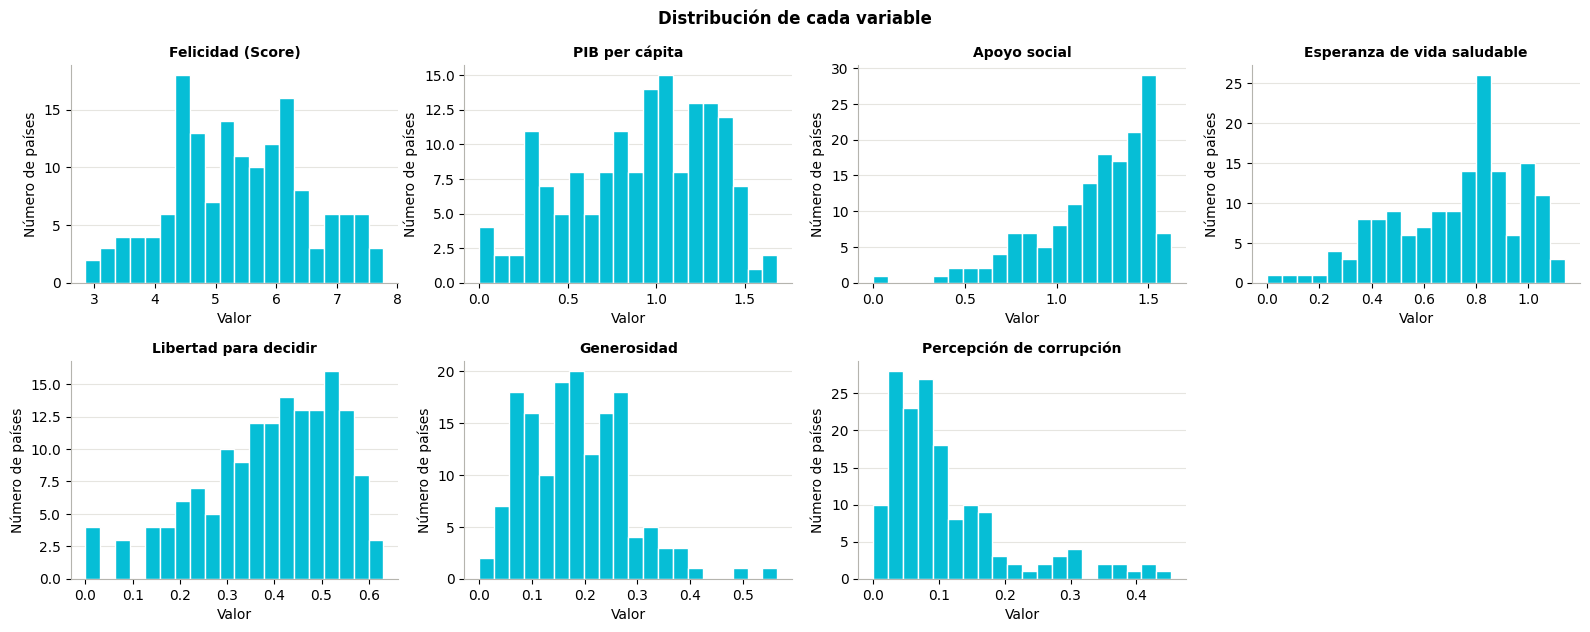

Asimetría de cada variable:
Score                           0.01
GDP per capita                 -0.39
Social support                 -1.13
Healthy life expectancy        -0.61
Freedom to make life choices   -0.69
Generosity                      0.75
Perceptions of corruption       1.65
dtype: float64


In [ ]:
def graficar_histogramas(datos, columnas, columnas_por_fila=4):
    """Histograma por cada columna para ver su distribución.
    Parameters
    ----------
    datos : pandas.DataFrame
        Tabla con los datos.
    columnas : list of str
        Columnas que se van a graficar.
    columnas_por_fila : int, default=4
        Número de gráficas por renglón.
    """
    filas = int(np.ceil(len(columnas) / columnas_por_fila))
    fig, ejes = plt.subplots(filas, columnas_por_fila, figsize=(4 * columnas_por_fila, 3.2 * filas))
    ejes = np.ravel(ejes)
    for eje, col in zip(ejes, columnas):
        eje.hist(datos[col], bins=20, color=AZUL, edgecolor="white", linewidth=1)
        eje.set_title(ETIQUETAS.get(col, col), fontsize=10)
        eje.set_xlabel("Valor")
        eje.set_ylabel("Número de países")
        eje.grid(axis="x", visible=False)
    for eje in ejes[len(columnas):]:
        eje.set_visible(False)
    fig.suptitle("Distribución de cada variable", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_histogramas(df, COLUMNAS_EDA)
print("Asimetría de cada variable:")
print(df[COLUMNAS_EDA].skew().round(2))

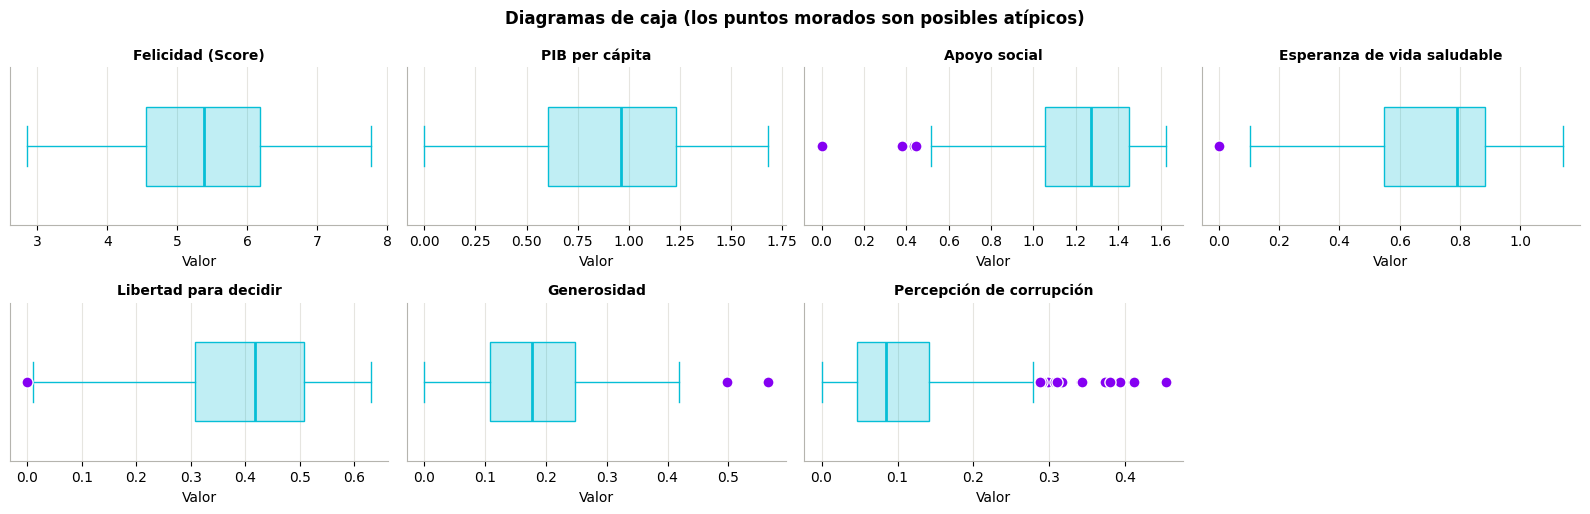

In [ ]:
def graficar_boxplots(datos, columnas, columnas_por_fila=4):
    """Diagrama de caja por columna para detectar valores atípicos.
    Parameters
    ----------
    datos : pandas.DataFrame
        Tabla con los datos.
    columnas : list of str
        Columnas que se van a graficar.
    columnas_por_fila : int, default=4
        Número de gráficas por renglón.
    """
    filas = int(np.ceil(len(columnas) / columnas_por_fila))
    fig, ejes = plt.subplots(filas, columnas_por_fila, figsize=(4 * columnas_por_fila, 2.6 * filas))
    ejes = np.ravel(ejes)
    for eje, col in zip(ejes, columnas):
        eje.boxplot(datos[col], vert=False, widths=0.5, patch_artist=True,
                    boxprops=dict(facecolor=to_rgba(AZUL, 0.25), edgecolor=AZUL),
                    medianprops=dict(color=AZUL, linewidth=2),
                    whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
                    flierprops=dict(marker="o", markerfacecolor=MORADO, markeredgecolor="white", markersize=8))
        eje.set_title(ETIQUETAS.get(col, col), fontsize=10)
        eje.set_xlabel("Valor")
        eje.set_yticks([])
    for eje in ejes[len(columnas):]:
        eje.set_visible(False)
    fig.suptitle("Diagramas de caja (los puntos morados son posibles atípicos)", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_boxplots(df, COLUMNAS_EDA)

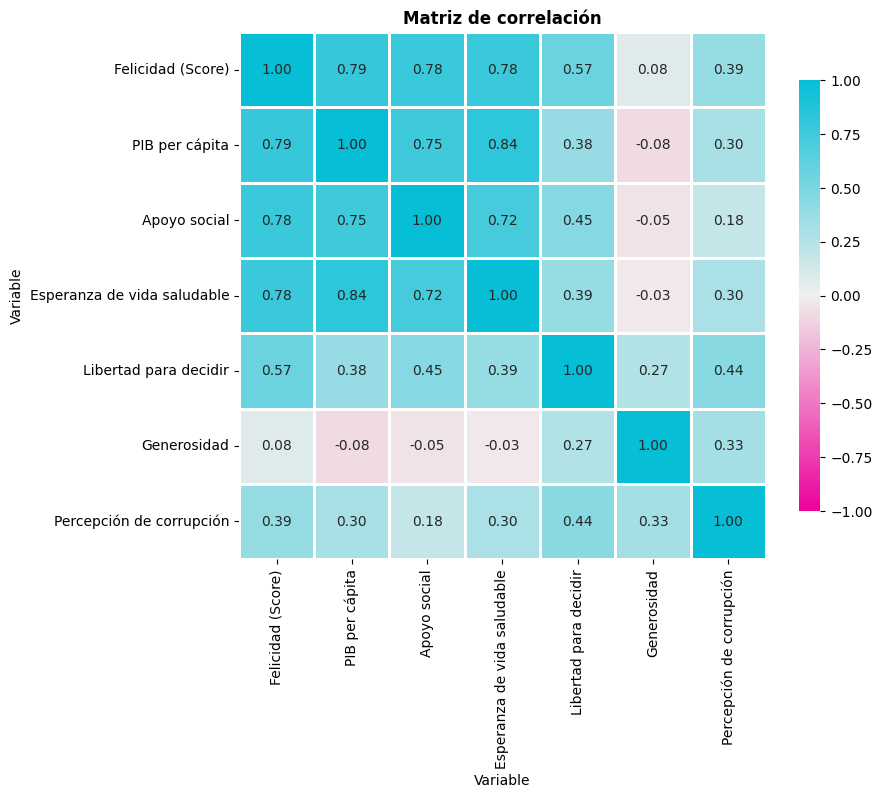

In [ ]:
def graficar_correlacion(datos, titulo="Matriz de correlación"):
    """Matriz de correlación de Pearson como mapa de calor.
    Usa una escala divergente: rosa para correlación negativa, gris para cero
    y azul para correlación positiva.
    Parameters
    ----------
    datos : pandas.DataFrame
        Tabla con variables numéricas.
    titulo : str, default="Matriz de correlación"
        Título de la gráfica.
    """
    escala = LinearSegmentedColormap.from_list("divergente", [ROSA, "#f0efec", AZUL])
    fig, eje = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(datos.corr(), annot=True, fmt=".2f", cmap=escala, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8}, ax=eje)
    eje.set_title(titulo)
    eje.set_xlabel("Variable")
    eje.set_ylabel("Variable")
    eje.grid(False)
    plt.show()


graficar_correlacion(df[COLUMNAS_EDA].rename(columns=ETIQUETAS))

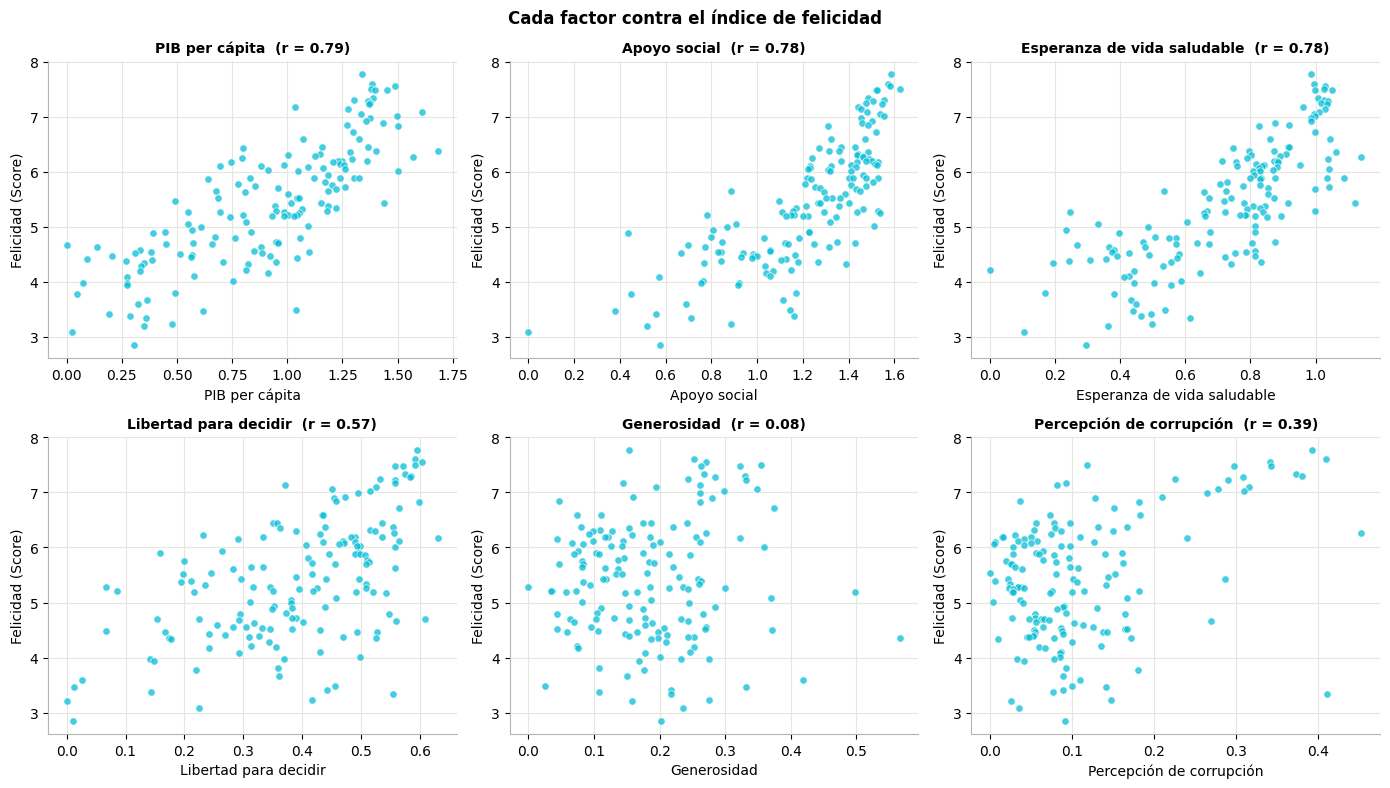

In [ ]:
def graficar_dispersion_vs_objetivo(datos, predictoras, objetivo):
    """Grafica cada variable predictora contra la variable objetivo.
    En el título de cada gráfica se muestra la correlación (r) entre la
    predictora y el objetivo.
    Parameters
    ----------
    datos : pandas.DataFrame
        Tabla con los datos.
    predictoras : list of str
        Columnas que van en el eje x (una gráfica por columna).
    objetivo : str
        Columna que va en el eje y.
    """
    fig, ejes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
    for eje, col in zip(ejes.ravel(), predictoras):
        eje.scatter(datos[col], datos[objetivo], s=28, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.6)
        r = datos[col].corr(datos[objetivo])
        eje.set_title(f"{ETIQUETAS.get(col, col)}  (r = {r:.2f})", fontsize=10)
        eje.set_xlabel(ETIQUETAS.get(col, col))
        eje.set_ylabel(ETIQUETAS.get(objetivo, objetivo))
        eje.tick_params(labelleft=True)
    fig.suptitle("Cada factor contra el índice de felicidad", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_dispersion_vs_objetivo(df, COLUMNAS_EDA[1:], "Score")

**Observaciones:**

Vemos que el dataset tiene 7 columnas numéricas, además del ranking y el nombre del país, y no hay filas repetidas ni países duplicados. El índice de felicidad va desde 2.853, que es South Sudan, hasta 7.769, que es Finlandia, y el promedio es de 5.407. En el histograma se ve que la felicidad está más o menos equilibrada, no está cargada hacia ningún lado. Los seis factores tienen valores parecidos, casi todos entre 0 y 1.7, porque el reporte los mide como lo que aporta cada uno a la felicidad. La percepción de corrupción es diferente, casi todos los países tienen valores bajos y solo unos pocos, como los nórdicos, Singapur o Nueva Zelanda, tienen valores altos. Aquí hay que tener en cuenta que un valor alto significa que la gente percibe menos corrupción, no más.

En la matriz de correlación vemos que lo que más se relaciona con la felicidad es el PIB con 0.79, la esperanza de vida con 0.78 y el apoyo social con 0.78, después sigue la libertad con 0.57 y la corrupción con 0.39. La generosidad casi no tiene relación, solo 0.08. También nos dimos cuenta de que algunas variables están muy relacionadas entre ellas, por ejemplo el PIB y la esperanza de vida tienen 0.84, entonces puede haber multicolinealidad y eso lo revisamos en el paso 5. En las gráficas de dispersión los puntos del PIB, el apoyo social y la esperanza de vida forman más o menos una línea hacia arriba, por eso tiene sentido usar una regresión lineal.

## 4. Limpieza de datos

In [ ]:
NOMBRES_NUEVOS = {
    "Score": "felicidad",
    "GDP per capita": "pib_per_capita",
    "Social support": "apoyo_social",
    "Healthy life expectancy": "esperanza_vida",
    "Freedom to make life choices": "libertad",
    "Generosity": "generosidad",
    "Perceptions of corruption": "percepcion_corrupcion",
}

In [ ]:
def limpiar_datos(datos):
    """Limpia el dataset del World Happiness Report 2019.
    Pasos:
    1. Usa el nombre del país como índice (para identificar cada fila).
    2. Elimina Overall rank, porque se calcula a partir del propio Score.
    3. Renombra las columnas a nombres cortos en español.
    4. Elimina filas duplicadas y filas con valores nulos (si es que hubiera).
    Parameters
    ----------
    datos : pandas.DataFrame
        Dataset original tal como se cargó del CSV.
    Returns
    -------
    pandas.DataFrame
        Dataset limpio, con el país como índice.
    """
    limpio = (datos.copy()
              .set_index("Country or region")
              .drop(columns=["Overall rank"])
              .rename(columns=NOMBRES_NUEVOS)
              .drop_duplicates()
              .dropna())
    limpio.index.name = "pais"
    return limpio


df_limpio = limpiar_datos(df)
print("Tamaño antes:", df.shape)
print("Después:", df_limpio.shape)

Tamaño antes: (156, 9)
Después: (156, 7)


In [ ]:
df_limpio.head()

,felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,percepcion_corrupcion
pais,,,,,,,
Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


Hay que revisar qué países tienen ceros

In [ ]:
ceros = df_limpio.drop(columns="felicidad").eq(0)
for col in ceros.columns:
    paises = list(df_limpio.index[ceros[col]])
    print(f"{col:<22} ceros: {len(paises)}  {paises}")

pib_per_capita         ceros: 1  ['Somalia']
apoyo_social           ceros: 1  ['Central African Republic']
esperanza_vida         ceros: 1  ['Swaziland']
libertad               ceros: 1  ['Afghanistan']
generosidad            ceros: 1  ['Greece']
percepcion_corrupcion  ceros: 1  ['Moldova']


In [ ]:
def contar_outliers_iqr(datos):
    """Cuenta los valores atípicos de cada columna con la regla del rango intercuartílico.
    Un valor es atípico si está por debajo de Q1 - 1.5*IQR o por arriba de
    Q3 + 1.5*IQR, donde IQR = Q3 - Q1.
    Parameters
    ----------
    datos : pandas.DataFrame
        Tabla con variables numéricas; el índice identifica cada fila.

    Returns
    -------
    pandas.DataFrame
        Número de atípicos por columna y las filas (países) donde aparecen.
    """
    resumen = []
    for col in datos.columns:
        q1, q3 = datos[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        atipicos = datos[(datos[col] < q1 - 1.5 * iqr) | (datos[col] > q3 + 1.5 * iqr)]
        resumen.append({"variable": col, "n_atipicos": len(atipicos),
                        "paises": ", ".join(atipicos.index)})
    return pd.DataFrame(resumen)


with pd.option_context("display.max_colwidth", None):
    display(contar_outliers_iqr(df_limpio))

,variable,n_atipicos,paises
0,felicidad,0,
1,pib_per_capita,0,
2,apoyo_social,4,"Benin, Burundi, Syria, Central African Republic"
3,esperanza_vida,1,Swaziland
4,libertad,1,Afghanistan
5,generosidad,2,"Indonesia, Myanmar"
6,percepcion_corrupcion,14,"Finland, Denmark, Norway, Netherlands, Switzerland, Sweden, New Zealand, Canada, Australia, Luxembourg, Ireland, Singapore, Hong Kong, Rwanda"


*with pd.option_context("display.max_colwidth", None):
    display(contar_outliers_iqr(df_limpio))*

Este código muestra en pantalla el resultado de la función contar_outliers_iqr(df_limpio) utilizando de forma temporal un ancho de celda ilimitado (None), lo que evita que los textos largos se recorten con puntos suspensivos y garantiza que toda la información se visualice completa.

**Observaciones:**

No encontramos valores nulos ni duplicados, así que no tuvimos que eliminar ni rellenar nada y nos quedamos con los 156 países. Lo que sí hicimos fue quitar la columna Overall rank, porque el ranking se saca ordenando el mismo Score y si la dejábamos el modelo prácticamente ya tendría la respuesta. El país lo pusimos como índice para poder identificar cada fila más adelante, y cambiamos los nombres de las columnas a español para que fuera más fácil leerlas.

Al revisar los ceros vimos que cada factor tiene un país con 0, por ejemplo Somalia en PIB, Swaziland en esperanza de vida y Afghanistan en libertad. Podría parecer que son errores, pero no lo son, porque el reporte compara cada factor con un país imaginario que tiene los peores valores (le llaman Distopía), entonces un 0 quiere decir que ese país está igual que ese mínimo. Con la regla del IQR salieron 14 atípicos en percepción de corrupción, pero son países reales con muy poca corrupción como Finlandia, Dinamarca o Noruega. En las demás variables salieron muy pocos, 4 en apoyo social, 2 en generosidad y 1 en esperanza de vida y en libertad. Decidimos no quitar ninguno porque son datos reales y además con solo 156 países no queríamos perder información.

## 5. Selección de variables

In [ ]:
OBJETIVO = "felicidad" #score
correlaciones = (df_limpio.corr()[OBJETIVO]
                 .drop(OBJETIVO)
                 .sort_values(ascending=False)
                 .rename("correlación con felicidad"))
correlaciones.to_frame()

,correlación con felicidad
pib_per_capita,0.794
esperanza_vida,0.780
apoyo_social,0.777
libertad,0.567
percepcion_corrupcion,0.386
generosidad,0.076


In [ ]:
def calcular_vif(X):
    """Calcula el factor de inflación de la varianza (VIF) de cada variable.
    El VIF de una variable se obtiene ajustando una regresión lineal de esa
    variable contra todas las demás: VIF = 1 / (1 - R2). Un VIF mayor a 5
    indica multicolinealidad fuerte.
    Parameters
    ----------
    X : pandas.DataFrame
        Variables predictoras.
    Returns
    -------
    pandas.Series
        VIF de cada variable, ordenado de mayor a menor.
    """
    vif = {}
    for col in X.columns:
        otras = X.drop(columns=col)
        r2 = LinearRegression().fit(otras, X[col]).score(otras, X[col])
        vif[col] = 1 / (1 - r2)
    return pd.Series(vif, name="VIF").sort_values(ascending=False)


calcular_vif(df_limpio.drop(columns=OBJETIVO)).to_frame()

,VIF
pib_per_capita,4.116
esperanza_vida,3.573
apoyo_social,2.736
libertad,1.575
percepcion_corrupcion,1.432
generosidad,1.224


Calculamos el Factor de Inflación de la Varianza (VIF) para comprobar si existía redundancia o colinealidad excesiva entre nuestras variables. Los resultados mostraron que, aunque el PIB per cápita y la esperanza de vida presentan los valores más altos (alrededor de 4 y 3.5 respectivamente), **ninguno supera los umbrales críticos (5 - 10) de alerta, lo que valida que podemos utilizar todas las variables predictoras de forma segura en nuestro modelo de regresión**

In [ ]:
PREDICTORAS = ["pib_per_capita", "apoyo_social", "esperanza_vida",
               "libertad", "generosidad", "percepcion_corrupcion"]

In [ ]:
X = df_limpio[PREDICTORAS]
y = df_limpio[OBJETIVO]
print("X:", X.shape, "| y:", y.shape)

X: (156, 6) | y: (156,)


**Observaciones:**

Con las correlaciones confirmamos que los factores que más se relacionan con la felicidad son el PIB, la esperanza de vida y el apoyo social, y que la generosidad casi no tiene que ver, con apenas 0.08. Para revisar la multicolinealidad calculamos el VIF, que básicamente mide qué tanto se puede explicar una variable con las demás. Todas salieron con un VIF menor a 5, la más alta fue el PIB con 4.12, entonces sí hay algo de relación entre ellas pero no es tan grave como para quitar alguna. Por eso decidimos quedarnos con las seis variables, son pocas y todas tienen sentido para explicar la felicidad. Aunque la generosidad parece no aportar mucho, la dejamos para ver qué pasa con Lasso en el paso 13.

## 6. División train/test : 80-20

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)

print(f"Entrenamiento: {X_train.shape[0]} países ({X_train.shape[0] / len(X):.1%})")
print(f"Prueba:        {X_test.shape[0]} países ({X_test.shape[0] / len(X):.1%})")
pd.DataFrame({"entrenamiento": y_train.describe(), "prueba": y_test.describe()}).T

Entrenamiento: 124 países (79.5%)
Prueba:        32 países (20.5%)


,count,mean,std,min,25%,50%,75%,max
entrenamiento,124.0,5.395,1.136,2.853,4.517,5.408,6.176,7.769
prueba,32.0,5.455,1.036,3.231,4.861,5.329,6.305,7.246


**Observaciones:**

Separamos los datos en 124 países para entrenar y 32 para probar, que es el 80% y 20%, aunque como 156 no se divide exacto queda en 79.5% y 20.5%. Usamos random_state igual a 42 para que siempre salga la misma división. El promedio de felicidad en los dos grupos es muy parecido, 5.395 en entrenamiento y 5.455 en prueba, así que la división quedó bien repartida. Algo que hay que tomar en cuenta es que el grupo de prueba es pequeño, entonces los resultados pueden cambiar mucho dependiendo de qué países caigan ahí, por eso también hacemos validación cruzada.

## 7. Escalado de datos

In [ ]:
def construir_pipeline(modelo=None):
    """Crea un Pipeline que escala los datos y después entrena un modelo de regresión.
    Al usar un Pipeline, el StandardScaler se ajusta solo con los datos de
    entrenamiento (y, en la validación cruzada, solo con los folds de
    entrenamiento), lo que evita la fuga de información.
    Parameters
    ----------
    modelo : estimador de scikit-learn, opcional
        Modelo de regresión que va al final del pipeline. Si no se indica,
        se usa LinearRegression().
    Returns
    -------
    sklearn.pipeline.Pipeline
        Pipeline con los pasos "escalador" (StandardScaler) y "modelo".
    """
    if modelo is None:
        modelo = LinearRegression()
    return Pipeline([("escalador", StandardScaler()), ("modelo", modelo)])

Solo para mostrar el efecto del escalado, aunque dentro del pipeline se hace automáticamente

In [ ]:
escalador_demo = StandardScaler().fit(X_train)
X_train_escalado = pd.DataFrame(escalador_demo.transform(X_train), columns=PREDICTORAS, index=X_train.index)

(pd.DataFrame({
    "media antes": X_train.mean(),
    "desv. antes": X_train.std(ddof=0),
    "media después": X_train_escalado.mean(),
    "desv. después": X_train_escalado.std(ddof=0),
}).round(3) + 0.0)

,media antes,desv. antes,media después,desv. después
pib_per_capita,0.896,0.415,0.0,1.0
apoyo_social,1.198,0.303,0.0,1.0
esperanza_vida,0.725,0.249,0.0,1.0
libertad,0.390,0.150,0.0,1.0
generosidad,0.184,0.097,0.0,1.0
percepcion_corrupcion,0.116,0.100,0.0,1.0


**Observaciones:**

Usamos StandardScaler, que lo que hace es dejar cada variable con promedio 0 y desviación estándar 1. En la tabla se ve que antes del escalado las variables tenían escalas diferentes, por ejemplo el apoyo social tenía un promedio de casi 1.2 y la corrupción de apenas 0.12, y después del escalado todas quedan en la misma escala. Esto nos sirve para poder comparar los coeficientes más adelante. El escalador solo aprende con los datos de entrenamiento y luego se aplica igual a los de prueba, y como lo metimos dentro del pipeline, en la validación cruzada se vuelve a ajustar en cada parte, así el modelo no ve información de los datos con los que se va a evaluar.

## 8. Entrenar modelo

In [ ]:
modelo_base = construir_pipeline()
modelo_base.fit(X_train, y_train)
modelo_base

Pipeline(steps=[('escalador', StandardScaler()),
                ('modelo', LinearRegression())])

**Observaciones:**

El modelo quedó como un pipeline de dos pasos, primero escala los datos y luego hace la regresión lineal. Lo entrenamos solamente con los 124 países de entrenamiento, los 32 de prueba todavía no los usamos para nada.

## 9. Validación cruzada: k=5

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {"R2": "r2", "MSE": "neg_mean_squared_error", "MAE": "neg_mean_absolute_error"}

resultados_cv = cross_validate(construir_pipeline(), X_train, y_train, cv=kfold, scoring=metricas_cv)

tabla_cv = pd.DataFrame({
    "R2": resultados_cv["test_R2"],
    "MSE": -resultados_cv["test_MSE"],
    "RMSE": np.sqrt(-resultados_cv["test_MSE"]),
    "MAE": -resultados_cv["test_MAE"],
}, index=[f"Fold {i}" for i in range(1, 6)])
folds = tabla_cv.copy()
tabla_cv.loc["Promedio"] = folds.mean()
tabla_cv.loc["Desv. estándar"] = folds.std()
tabla_cv.round(3)

,R2,MSE,RMSE,MAE
Fold 1,0.800,0.183,0.428,0.353
Fold 2,0.818,0.232,0.481,0.396
Fold 3,0.742,0.373,0.611,0.504
Fold 4,0.784,0.401,0.633,0.457
Fold 5,0.735,0.208,0.456,0.379
Promedio,0.776,0.279,0.522,0.418
Desv. estándar,0.036,0.100,0.094,0.062


**Observaciones:**

Hicimos la validación cruzada con 5 partes usando solo los datos de entrenamiento, o sea que el modelo se entrena 5 veces con 4 partes y se prueba con la que sobra. El R2 salió entre 0.74 y 0.82 dependiendo de la parte, con un promedio de 0.78, y el RMSE promedio fue de 0.52 puntos. Como los resultados no cambian mucho de una parte a otra (la desviación del R2 fue de apenas 0.04), podemos decir que el modelo es bastante estable y no depende tanto de qué países le toquen.

## 10. Predicción

In [ ]:
y_pred_train = modelo_base.predict(X_train)
y_pred_test = modelo_base.predict(X_test)

predicciones = pd.DataFrame({"real": y_test, "predicho": y_pred_test})
predicciones["error"] = predicciones["real"] - predicciones["predicho"]
print("Los 10 países de prueba con mayor error:")
predicciones.sort_values("error", key=abs, ascending=False).head(10).round(3)

Los 10 países de prueba con mayor error:


,real,predicho,error
pais,,,
Botswana,3.488,5.301,-1.813
Tanzania,3.231,4.583,-1.352
Benin,4.883,3.673,1.210
Israel,7.139,6.235,0.904
Ivory Coast,4.944,4.117,0.827
Ukraine,4.332,5.155,-0.823
India,4.015,4.759,-0.744
Bulgaria,5.011,5.744,-0.733
Czech Republic,6.852,6.186,0.666


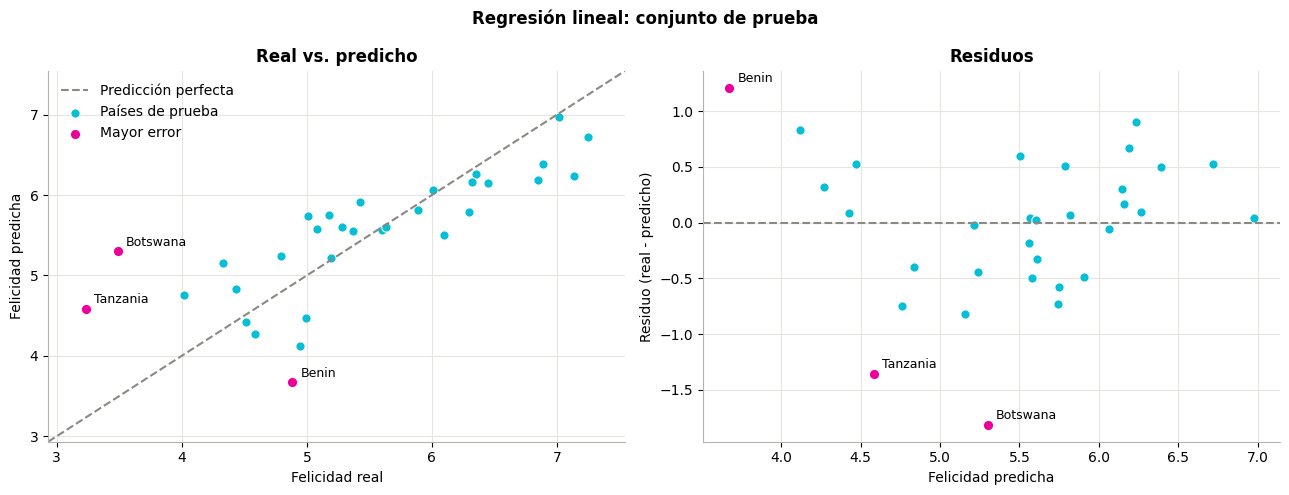

In [ ]:
def graficar_predicciones(y_real, y_predicho, titulo="Modelo", n_etiquetas=3):
    """Dibuja los valores reales contra los predichos y la gráfica de residuos.
    Los países con mayor error se marcan en rosa y con su nombre.
    Parameters
    ----------
    y_real : pandas.Series
        Valores reales; el índice debe tener el nombre del país.
    y_predicho : array-like
        Valores predichos por el modelo, en el mismo orden que ``y_real``.
    titulo : str, default="Modelo"
        Título general de la figura.
    n_etiquetas : int, default=3
        Número de países con mayor error que se etiquetan.
    """
    real = np.asarray(y_real)
    pred = np.asarray(y_predicho)
    residuos = real - pred
    peores = np.argsort(-np.abs(residuos))[:n_etiquetas]

    fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 5))
    limites = [min(real.min(), pred.min()) - 0.3, max(real.max(), pred.max()) + 0.3]
    eje1.plot(limites, limites, color=GRIS, linestyle="--", linewidth=1.5, label="Predicción perfecta")
    eje1.scatter(real, pred, s=45, color=AZUL, edgecolor="white", linewidth=0.8, label="Países de prueba")
    eje1.scatter(real[peores], pred[peores], s=55, color=ROSA, edgecolor="white", linewidth=0.8,
                 label="Mayor error")
    eje1.set(xlim=limites, ylim=limites, xlabel="Felicidad real", ylabel="Felicidad predicha",
             title="Real vs. predicho")
    eje1.legend(frameon=False, loc="upper left")

    eje2.axhline(0, color=GRIS, linestyle="--", linewidth=1.5)
    eje2.scatter(pred, residuos, s=45, color=AZUL, edgecolor="white", linewidth=0.8)
    eje2.scatter(pred[peores], residuos[peores], s=55, color=ROSA, edgecolor="white", linewidth=0.8)
    eje2.set(xlabel="Felicidad predicha", ylabel="Residuo (real - predicho)", title="Residuos")

    for i in peores:
        eje1.annotate(y_real.index[i], (real[i], pred[i]), xytext=(6, 4), textcoords="offset points", fontsize=9)
        eje2.annotate(y_real.index[i], (pred[i], residuos[i]), xytext=(6, 4), textcoords="offset points", fontsize=9)

    fig.suptitle(titulo, fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_predicciones(y_test, y_pred_test, titulo="Regresión lineal: conjunto de prueba")

**Observaciones:**

En la gráfica de real contra predicho la mayoría de los puntos quedan cerca de la línea punteada, entonces el modelo predice bien a casi todos los países. El que más falló fue Botswana, que en realidad tiene 3.49 de felicidad pero el modelo le dio 5.30. Creemos que es porque tiene un PIB relativamente alto pero aun así es de los países menos felices, y eso una regresión lineal no lo puede captar. También se equivocó con Tanzania, que tiene 3.23 y el modelo dijo 4.58, y con Benin pero al revés, porque tiene 4.88 y el modelo le dio 3.67. En la gráfica de residuos los puntos quedan arriba y abajo del 0 sin formar ningún patrón raro, lo que quiere decir que el modelo lineal sí es adecuado para estos datos.

## 11. Evaluación: MSE, RMSE, MAE, R2

In [ ]:
def evaluar_modelo(y_real, y_predicho):
    """Calcula las métricas de evaluación de un modelo de regresión.
    Parameters
    ----------
    y_real : array-like
        Valores reales.
    y_predicho : array-like
        Valores predichos por el modelo.
    Returns
    -------
    dict
        Diccionario con MSE, RMSE, MAE y R2.
    """
    mse = mean_squared_error(y_real, y_predicho)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_real, y_predicho),
        "R2": r2_score(y_real, y_predicho),
    }


tabla_metricas = pd.DataFrame({
    "Entrenamiento": evaluar_modelo(y_train, y_pred_train),
    "Validación cruzada (promedio)": tabla_cv.loc["Promedio", ["MSE", "RMSE", "MAE", "R2"]],
    "Prueba": evaluar_modelo(y_test, y_pred_test),
}).T
tabla_metricas.round(3)

,MSE,RMSE,MAE,R2
Entrenamiento,0.236,0.486,0.393,0.815
Validación cruzada (promedio),0.279,0.522,0.418,0.776
Prueba,0.414,0.644,0.495,0.602


Ahora, ¿cuánto del error de test viene de un solo país?

In [ ]:
error_cuadrado = predicciones["error"] ** 2
print(f"Parte del error cuadrático de prueba que aporta Botswana: {error_cuadrado['Botswana'] / error_cuadrado.sum():.0%}")

Parte del error cuadrático de prueba que aporta Botswana: 25%


**Observaciones:**

En entrenamiento el R2 fue de 0.815 y el RMSE de 0.486, en validación cruzada el R2 fue de 0.776 con un RMSE de 0.522, y en prueba el R2 bajó a 0.602, con un RMSE de 0.644 y un MAE de 0.495. Esto quiere decir que en promedio el modelo se equivoca por medio punto, en una escala donde la felicidad va de 2.9 a 7.8. Puede parecer raro que el R2 de prueba saliera más bajo, pero no creemos que sea sobreajuste porque entrenamiento y validación cruzada salieron muy parecidos. Lo que pasa es que en el grupo de prueba cayeron países difíciles, y nada más Botswana es como la cuarta parte de todo el error. Por eso confiamos más en la validación cruzada, que dice que el modelo explica más o menos el 78% de la felicidad.

## 12. Análisis de coeficientes

In [ ]:
def obtener_coeficientes(pipeline, nombres):
    """Extrae coeficientes del modelo que está al final de un pipeline.
    Parameters
    ----------
    pipeline : sklearn.pipeline.Pipeline
        Pipeline ya entrenado, con un paso llamado ``"modelo"``.
    nombres : list of str
        Nombres de las variables, en el mismo orden que las columnas de X.
    Returns
    -------
    pandas.DataFrame
        Tabla con el coeficiente de cada variable, ordenada por magnitud.
    """
    coef = pipeline.named_steps["modelo"].coef_
    tabla = pd.DataFrame({"variable": nombres, "coeficiente": coef})
    orden = tabla["coeficiente"].abs().sort_values(ascending=False).index
    return tabla.loc[orden].reset_index(drop=True)


coeficientes = obtener_coeficientes(modelo_base, PREDICTORAS)
print(f"Intercepto: {modelo_base.named_steps['modelo'].intercept_:.3f}")
print(f"Felicidad promedio en entrenamiento: {y_train.mean():.3f}")
coeficientes.round(3)

Intercepto: 5.395
Felicidad promedio en entrenamiento: 5.395


,variable,coeficiente
0,apoyo_social,0.374
1,pib_per_capita,0.312
2,esperanza_vida,0.232
3,libertad,0.223
4,percepcion_corrupcion,0.111
5,generosidad,0.026


Al analizar los coeficientes obtenidos por la regresión lineal, comprobamos que el apoyo social (0.374) y el PIB per cápita (0.312) son las variables con mayor peso e influencia positiva en el modelo, mientras que la generosidad confirma su bajo impacto con un coeficiente cercano a cero de 0.026

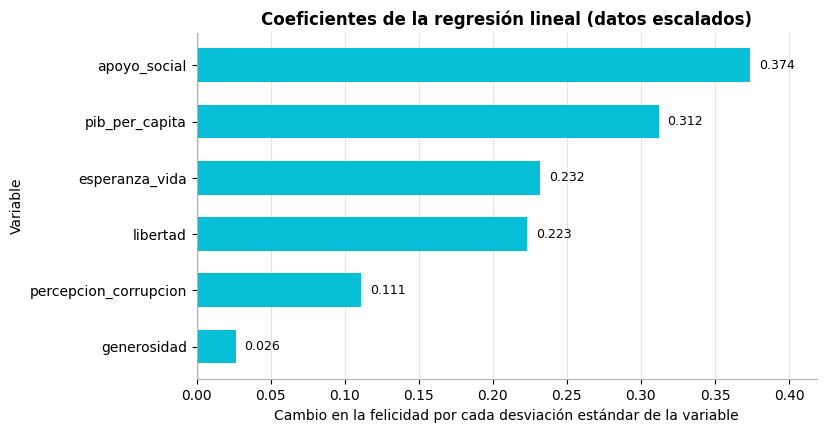

In [ ]:
def graficar_coeficientes(tabla, titulo):
    """Dibuja los coeficientes como barras horizontales, con su valor al lado.

    Parameters
    ----------
    tabla : pandas.DataFrame
        Tabla con las columnas ``"variable"`` y ``"coeficiente"``.
    titulo : str
        Título de la gráfica.
    """
    tabla = tabla.sort_values("coeficiente")
    fig, eje = plt.subplots(figsize=(8, 4.5))
    eje.barh(tabla["variable"], tabla["coeficiente"], color=AZUL, height=0.6)
    for posicion, valor in enumerate(tabla["coeficiente"]):
        eje.text(valor + (0.006 if valor >= 0 else -0.006), posicion, f"{valor:.3f}",
                 va="center", ha="left" if valor >= 0 else "right", fontsize=9)
    eje.axvline(0, color=GRIS, linewidth=1)
    eje.set_xlabel("Cambio en la felicidad por cada desviación estándar de la variable")
    eje.set_ylabel("Variable")
    eje.set_title(titulo)
    eje.grid(axis="y", visible=False)
    eje.margins(x=0.12)
    plt.show()


graficar_coeficientes(coeficientes, "Coeficientes de la regresión lineal (datos escalados)")

**Observaciones:**

Todos los coeficientes salieron positivos, o sea que entre más alto es cualquiera de los factores, más feliz es el país (en el caso de la corrupción hay que recordar que un valor alto significa menos corrupción). Como escalamos los datos, cada coeficiente nos dice cuánto sube la felicidad si esa variable aumenta una desviación estándar y las demás se quedan igual. El que más pesa es el apoyo social con 0.374, después el PIB con 0.312, la esperanza de vida con 0.232 y la libertad con 0.223, la corrupción tiene 0.111 y la generosidad casi nada con 0.026. El intercepto salió de 5.395, que es lo mismo que el promedio de felicidad en entrenamiento, y tiene sentido porque al escalar los datos todas las variables quedan con promedio 0.

Algo que nos llamó la atención es que el PIB era la variable con más correlación con la felicidad, pero en el modelo pesa más el apoyo social. Creemos que es porque el PIB y la esperanza de vida están muy relacionados entre sí y se reparten el efecto. Por eso hay que tener cuidado y no tomar los coeficientes como si una cosa causara la otra, solo nos dicen qué se relaciona más con la felicidad.

## 13. Ajuste de hiperparámetros

LinearRegression casi no tiene hiperparámetros que ajustar, así que se prueban sus versiones con regularización, que sí tienen uno: alpha.

**Ridge** (regularización L2): reduce el tamaño de todos los coeficientes.

**Lasso** (regularización L1): puede llevar coeficientes exactamente a 0, es decir, quitar variables.

Se usa GridSearchCV con la misma validación cruzada de k = 5, probando 13 valores de alpha entre 0.001 y 1000.

In [ ]:
alphas = np.logspace(-3, 3, 13)

busqueda_ridge = GridSearchCV(construir_pipeline(Ridge()), {"modelo__alpha": alphas},
                              cv=kfold, scoring="neg_mean_squared_error")
busqueda_ridge.fit(X_train, y_train)

busqueda_lasso = GridSearchCV(construir_pipeline(Lasso(max_iter=10000)), {"modelo__alpha": alphas},
                              cv=kfold, scoring="neg_mean_squared_error")
busqueda_lasso.fit(X_train, y_train)

alpha_ridge = busqueda_ridge.best_params_["modelo__alpha"]
alpha_lasso = busqueda_lasso.best_params_["modelo__alpha"]
print(f"Mejor alpha para Ridge: {alpha_ridge:.4g}")
print(f"Mejor alpha para Lasso: {alpha_lasso:.4g}")

Mejor alpha para Ridge: 31.62
Mejor alpha para Lasso: 0.03162


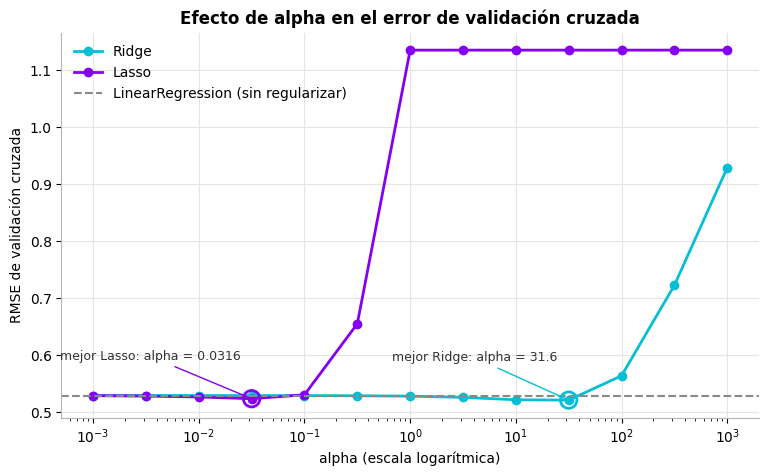

In [ ]:
# RMSE de validación cruzada del modelo sin regularizar (misma forma de calcularlo que GridSearchCV)
rmse_cv_base = np.sqrt(-resultados_cv["test_MSE"].mean())

fig, eje = plt.subplots(figsize=(9, 5))
for busqueda, nombre, color in [(busqueda_ridge, "Ridge", AZUL), (busqueda_lasso, "Lasso", MORADO)]:
    rmse = np.sqrt(-busqueda.cv_results_["mean_test_score"])
    eje.plot(alphas, rmse, marker="o", markersize=6, linewidth=2, color=color, label=nombre)
    # Marcamos el mejor alpha de cada modelo
    mejor = busqueda.best_index_
    eje.scatter(alphas[mejor], rmse[mejor], s=140, facecolor="none", edgecolor=color, linewidth=2, zorder=3)
    eje.annotate(f"mejor {nombre}: alpha = {alphas[mejor]:.3g}", (alphas[mejor], rmse[mejor]),
                 xytext=(-8, 28), textcoords="offset points", ha="right", fontsize=9, color="#333333",
                 arrowprops=dict(arrowstyle="-", color=color, linewidth=1))
eje.axhline(rmse_cv_base, color=GRIS, linestyle="--", linewidth=1.5, label="LinearRegression (sin regularizar)")
eje.set_xscale("log")
eje.set(xlabel="alpha (escala logarítmica)", ylabel="RMSE de validación cruzada",
        title="Efecto de alpha en el error de validación cruzada")
eje.legend(frameon=False)
plt.show()

In [ ]:
modelos = {
    "LinearRegression": (modelo_base, rmse_cv_base),
    f"Ridge (alpha={alpha_ridge:.3g})": (busqueda_ridge.best_estimator_, np.sqrt(-busqueda_ridge.best_score_)),
    f"Lasso (alpha={alpha_lasso:.3g})": (busqueda_lasso.best_estimator_, np.sqrt(-busqueda_lasso.best_score_)),
}

In [ ]:
comparacion = {}
for nombre, (modelo, rmse_cv) in modelos.items():
    metricas_prueba = evaluar_modelo(y_test, modelo.predict(X_test))
    comparacion[nombre] = {"RMSE validación cruzada": rmse_cv,
                           **{f"{k} prueba": v for k, v in metricas_prueba.items()}}

pd.DataFrame(comparacion).T.round(3)

,RMSE validación cruzada,MSE prueba,RMSE prueba,MAE prueba,R2 prueba
LinearRegression,0.529,0.414,0.644,0.495,0.602
Ridge (alpha=31.6),0.520,0.418,0.646,0.503,0.599
Lasso (alpha=0.0316),0.523,0.420,0.648,0.499,0.596


In [ ]:
(pd.DataFrame({
    nombre: modelo.named_steps["modelo"].coef_ for nombre, (modelo, _) in modelos.items()
}, index=PREDICTORAS).round(3) + 0.0)

,LinearRegression,Ridge (alpha=31.6),Lasso (alpha=0.0316)
pib_per_capita,0.312,0.280,0.300
apoyo_social,0.374,0.317,0.359
esperanza_vida,0.232,0.242,0.225
libertad,0.223,0.209,0.219
generosidad,0.026,0.020,0.000
percepcion_corrupcion,0.111,0.111,0.099


Al comparar el modelo base de regresión lineal con las versiones regularizadas de Ridge y Lasso, observamos que las métricas de rendimiento son prácticamente iguales. Sin embargo, destaca el comportamiento de Lasso, que cumplió su función de selección automática al reducir el coeficiente de la generosidad exactamente a cero (0.000), confirmando de forma matemática que dicha variable no aporta valor predictivo significativo al estudio.

## 14. Interpretación

En general la regresión lineal funcionó bastante bien para predecir la felicidad de los países. Según la validación cruzada explica alrededor del 78% de la variación del índice de felicidad, y se equivoca más o menos por medio punto. En la prueba el R2 bajó a 0.60, pero eso fue sobre todo por algunos países difíciles de predecir como Botswana, Tanzania o Benin.

Lo que más influye en la felicidad según el modelo es el apoyo social, o sea tener a alguien con quien contar, seguido del PIB, la esperanza de vida y la libertad para tomar decisiones. La corrupción influye pero menos, y la generosidad prácticamente no tiene efecto, tanto que Lasso la eliminó. No vimos sobreajuste, porque los resultados de entrenamiento y de validación cruzada fueron parecidos y Ridge y Lasso casi no mejoraron nada.

También hay que decir que el modelo tiene sus limitaciones. Solo usamos 156 países de un solo año y el grupo de prueba fue pequeño. Además el PIB, la esperanza de vida y el apoyo social están relacionados entre sí, entonces no se puede separar del todo el efecto de cada uno, y el modelo solo muestra relaciones, no que una cosa cause la otra. Hay casos como Botswana que un modelo lineal simplemente no puede explicar. Para mejorarlo se podrían juntar los cinco años para tener más datos, agregar otras variables como la región, o probar un modelo no lineal como la regresión polinomial.

Como conclusión, con solo seis factores se puede predecir bastante bien qué tan feliz es un país, y lo que más se relaciona con la felicidad es el apoyo social y la economía, seguidos de la salud y la libertad.